In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

In [2]:
df = pd.read_csv('E:\DA Projects\Python Projects\EDA Telco Customer Chrun\Dataset\customer_churn_analysis\Telco-Customer-Churn.csv')

<>:1: SyntaxWarning: "\D" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\D"? A raw string is also an option.
<>:1: SyntaxWarning: "\D" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\D"? A raw string is also an option.
C:\Users\ashis\AppData\Local\Temp\ipykernel_16608\1459133929.py:1: SyntaxWarning: "\D" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\D"? A raw string is also an option.
  df = pd.read_csv('E:\DA Projects\Python Projects\EDA Telco Customer Chrun\Dataset\customer_churn_analysis\Telco-Customer-Churn.csv')


In [3]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


### Inspecting Data for EDA


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

###

    After Inspecting the data info i found that "TotalCharges" Column should be in float data type as the "MonthlyCharges"

###

###

    And there are some blanks available in the "TotalCharges" Column that i found when i inspected CSV which is easy to do

###

###

    Why are we doing ?
        => Because Tenure is 0 and no total charges are recorded

###


In [4]:
# Replace the blanks with 0
df['TotalCharges'] = df['TotalCharges'].replace(" ", '0')

# Converting type from 'str' to 'float'
df['TotalCharges'] = df['TotalCharges'].astype('float')

# Rechecking if the conversion was a success or not 
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [5]:
# checking if there are any null values
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [7]:
# Describe only works with the numberic columns available in the table
df.describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692,2279.734304
std,0.368612,24.559481,30.090047,2266.794470
min,0.000000,0.000000,18.250000,0.000000
25%,0.000000,9.000000,35.500000,398.550000
50%,0.000000,29.000000,70.350000,1394.550000
75%,0.000000,55.000000,89.850000,3786.600000
max,1.000000,72.000000,118.750000,8684.800000


In [6]:
# Checking duplicates in the dataframe as my 'customerID' 
    # column data should be unique

# Based on the entire rows in a table    
print(df.duplicated().sum())

# Based on the unique column
print(df['customerID'].duplicated().sum()) 

0
0


###

    Replaceing the values of "SeniorCitizen" as 0 = no and 1 = yes by using a function

###


In [7]:
def conv(value):
    if value == 1:
        return "Yes"
    else:
        return "No"
    
df['SeniorCitizen'] = df['SeniorCitizen'].apply(conv)

print(df['SeniorCitizen'].value_counts())
print(df['SeniorCitizen'].dtype)



SeniorCitizen
No     5901
Yes    1142
Name: count, dtype: int64
str


###

    customer churn distribution to compare customers who stayed (5,174) versus customers who left (1,869) using a count plot.

###


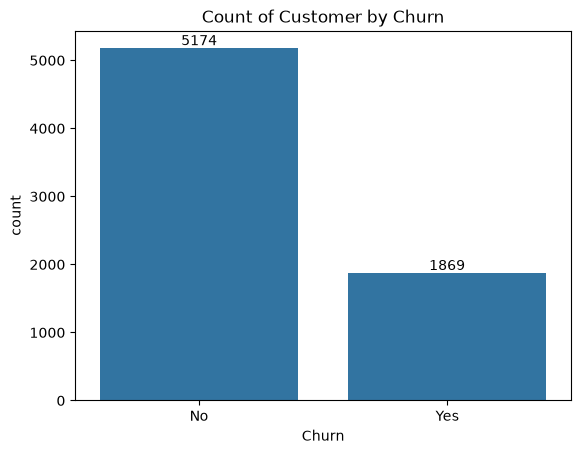

In [10]:
# Create a count plot to show the number of customers in each Churn category (Yes/No)
ax = sns.countplot(x = 'Churn', data = df)

# Display the count values on top of each bar
ax.bar_label(ax.containers[0])
plt.title('Count of Customer by Churn')
plt.show()

In [11]:
# for showing it in a percentage format we need to group the data based on 'Churn' column
# and aggregating it in a Dictionary format
gb = df.groupby('Churn').agg({'Churn':'count'})
gb

,Churn
Churn,
No,5174
Yes,1869


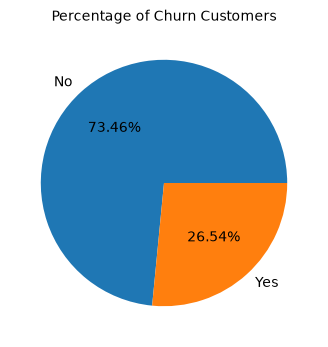

In [12]:
# ploting pie chart on the 'gb' dataframe 
# labels = index shows the numberic total count
# autopct = '%1.2f%%' formats it in a percentage 
plt.figure(figsize = (4, 4))
plt.pie(gb['Churn'], labels = gb.index, autopct ='%1.2f%%')
plt.title('Percentage of Churn Customers', fontsize =10)
plt.show()


# from the giving pie chart 26.54% of our customers have churned out.
# now let's explore the reason behind it

### Churn by Gender


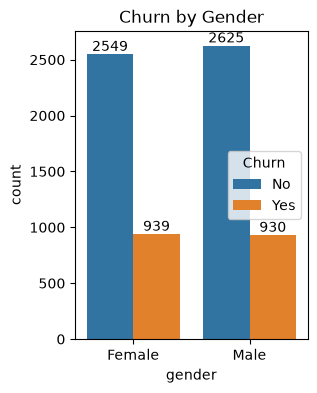

In [8]:
plt.figure(figsize = (3 , 4))
fig3 = sns.countplot(x = df['gender'], data = df, hue = 'Churn')
fig3.bar_label(fig3.containers[0])
fig3.bar_label(fig3.containers[1])
plt.title('Churn by Gender')
plt.show()

### Churn by Senior Citizen


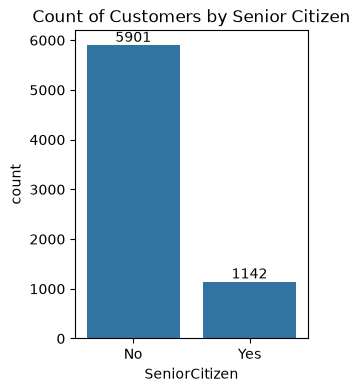

In [17]:
plt.figure(figsize = (3 , 4))
fig4 = sns.countplot(x = 'SeniorCitizen', data = df)
fig4.bar_label(fig4.containers[0])
plt.title('Count of Customers by Senior Citizen')
plt.show()

<Figure size 300x400 with 0 Axes>

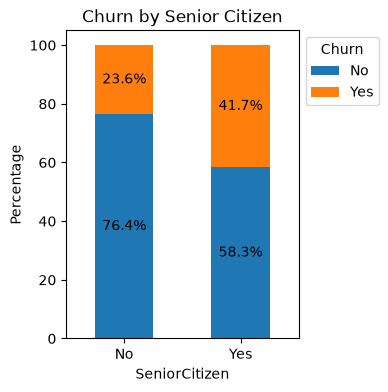

In [20]:
plt.figure(figsize = (3 , 4))
percent = pd.crosstab(df['SeniorCitizen'], df['Churn'], normalize='index') * 100

ax = percent.plot(kind='bar', stacked=True, figsize=(3, 4))

for container in ax.containers:
    labels = [f'{bar.get_height():.1f}%' for bar in container]
    ax.bar_label(container, labels=labels, label_type='center')

plt.title('Churn by Senior Citizen')
plt.ylabel('Percentage')
plt.xticks(rotation=0)
plt.legend(title = 'Churn', bbox_to_anchor= (1,1))
plt.show()

###

    Comparative a greated percentage of people in senior citizen category have churned

###


### Based on the Tenure


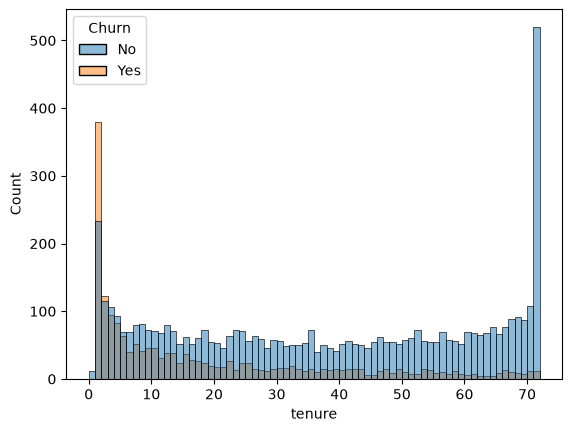

In [26]:
sns.histplot(x = 'tenure', data = df, bins= 72, hue = 'Churn')
plt.show()

###

    people who have used our services for a long time have stayed and people who have used our services for 1 or 2 months have churned

###


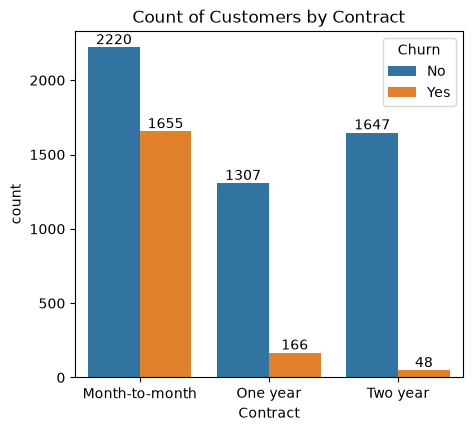

In [9]:
plt.figure(figsize = (5 , 4.5))
fig4 = sns.countplot(x = 'Contract', data = df, hue= 'Churn')
fig4.bar_label(fig4.containers[0])
fig4.bar_label(fig4.containers[1])
plt.title('Count of Customers by Contract')
plt.show()

###

    people who have MoM contract are likely to churn as compare to YoY or Two year contract
    (Recomendations: Convenince people/convert people to YoY or Two Year contract from MoM)

###


In [35]:
df.columns.values

<ArrowStringArray>
[      'customerID',           'gender',    'SeniorCitizen',
          'Partner',       'Dependents',           'tenure',
     'PhoneService',    'MultipleLines',  'InternetService',
   'OnlineSecurity',     'OnlineBackup', 'DeviceProtection',
      'TechSupport',      'StreamingTV',  'StreamingMovies',
         'Contract', 'PaperlessBilling',    'PaymentMethod',
   'MonthlyCharges',     'TotalCharges',            'Churn']
Length: 21, dtype: str

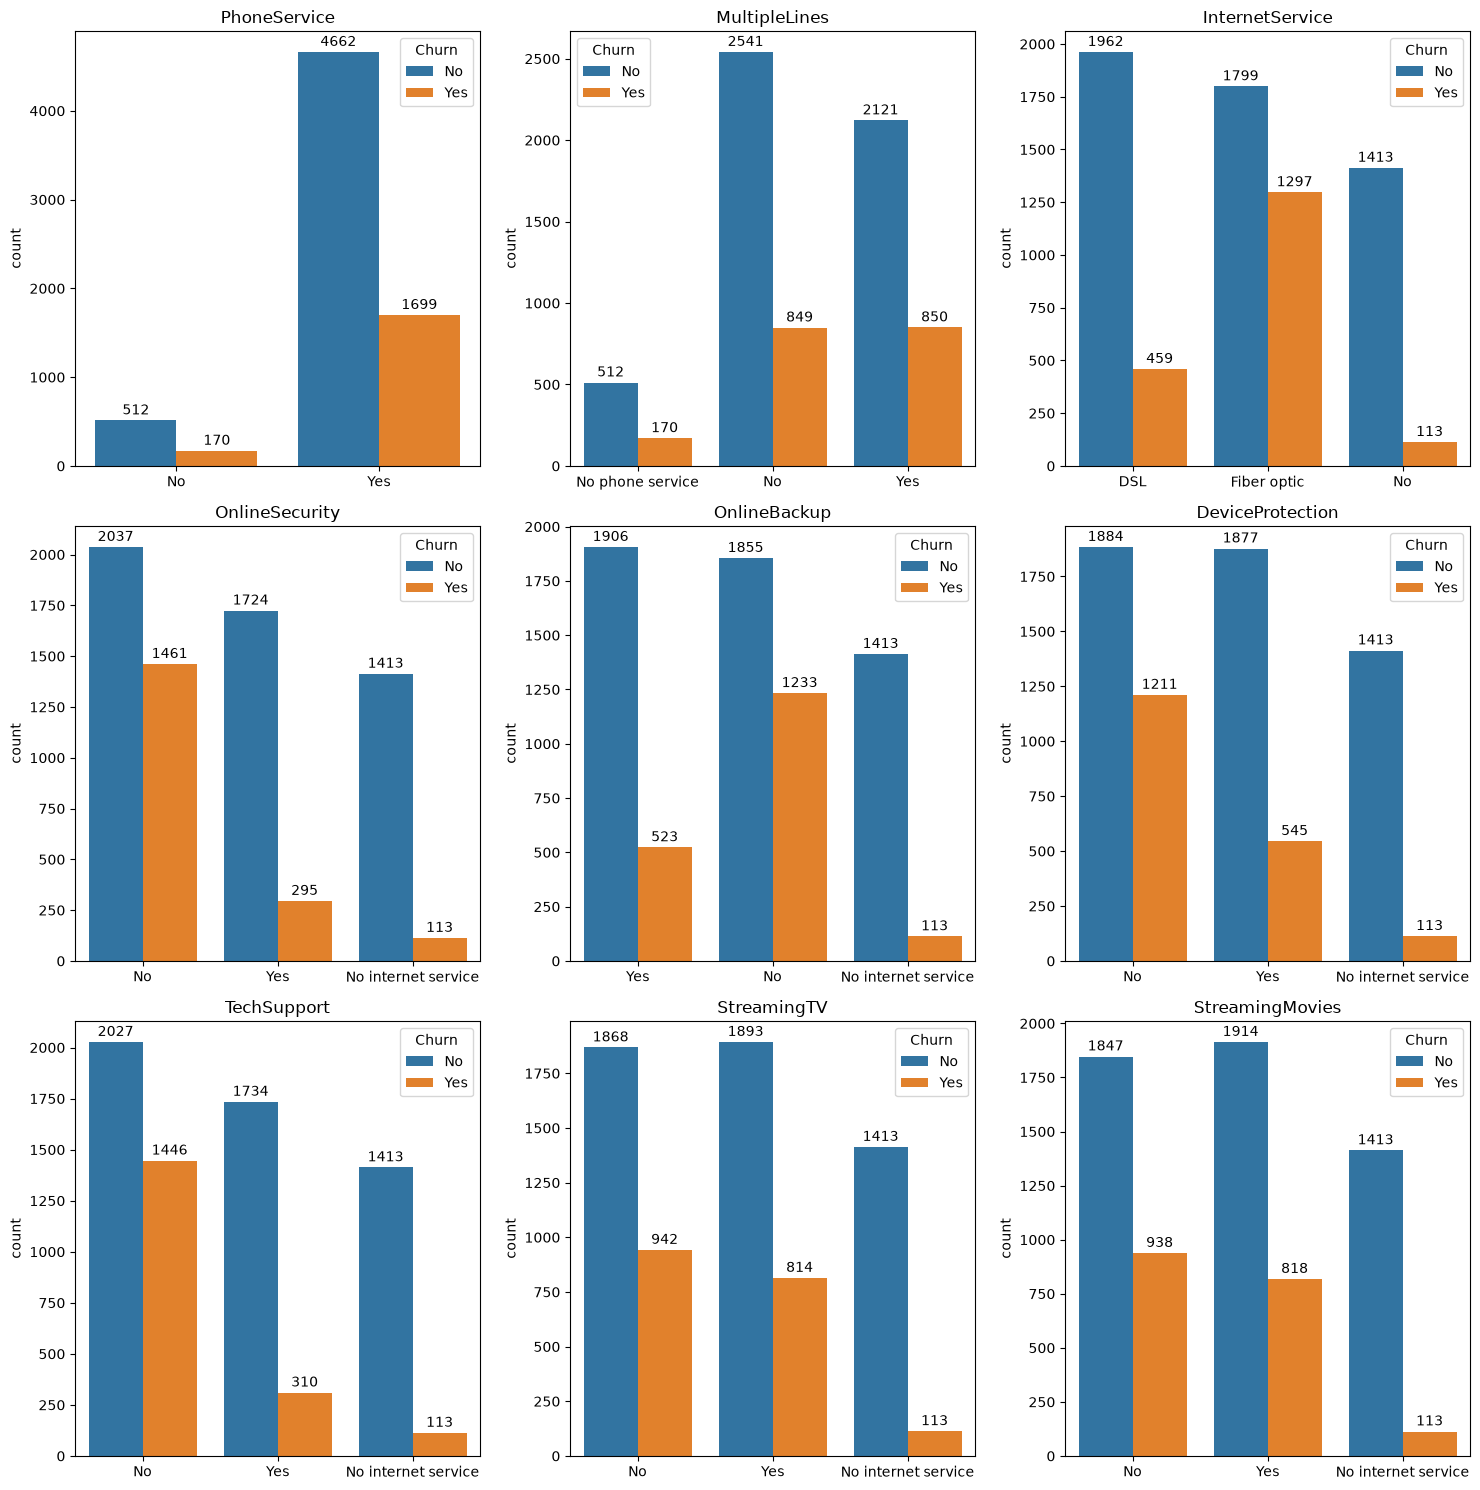

In [46]:
cols = ['PhoneService', 'MultipleLines', 'InternetService',
        'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
        'TechSupport', 'StreamingTV', 'StreamingMovies']

fig, axes = plt.subplots(3, 3, figsize=(15, 15))
axes = axes.flatten()

for i, col in enumerate(cols):
    sns.countplot(data=df, x=col, ax=axes[i], hue=df['Churn'])
    axes[i].set_title(col)
    axes[i].set_xlabel("")
    # axes[i].tick_params(axis='x', rotation=20)

    for container in axes[i].containers:
        axes[i].bar_label(container, padding=2)

plt.tight_layout()
plt.show()

### Summary (with exact numbers)

    Overall: 1,869 of 7,043 customers churned (about 26.5%). All rates below are calculated from the bar counts in your chart.

    Fiber optic is the biggest problem. 1,297 fiber customers churned out of 3,096, a 41.9% churn rate. That is more than double DSL (459 of 2,421, or 19.0%) and far above customers with no internet (113 of 1,526, or 7.4%). Fiber alone accounts for about 69% of all churners.

    Customers without protection and support add-ons leave the most.
    Service	Churn rate without it	Churn rate with it
    OnlineSecurity	1,461 of 3,498 = 41.8%	295 of 2,019 = 14.6%
    TechSupport	1,446 of 3,473 = 41.6%	310 of 2,044 = 15.2%
    OnlineBackup	1,233 of 3,088 = 39.9%	523 of 2,429 = 21.5%
    DeviceProtection	1,211 of 3,095 = 39.1%	545 of 2,422 = 22.5%
    Streaming, phone and multiple lines barely matter. StreamingTV (33.5% vs 30.1%) and StreamingMovies (33.7% vs 29.9%) differ by only about 4 points. PhoneService (24.9% vs 26.7%) and MultipleLines (25.0% vs 28.6%) are also close, so these are weak churn predictors.

    Customers with no internet are the most loyal. Their churn rate is only 7.4% (113 of 1,526) in every internet-related column.


    Recommendations
    Investigate fiber optic first. Check pricing against competitors, outages, speed complaints and support tickets. Fixing a 41.9% churn rate here would have the biggest impact.

    Bundle OnlineSecurity and TechSupport for free or at a discount for new fiber customers, since users with these churn at only about 15%.

    Run targeted offers for customers who have no security, backup, protection or support add-ons, as they are the highest-risk group (about 40% churn).

    Don’t spend retention budget on streaming or phone features, because they show little difference in churn.

###


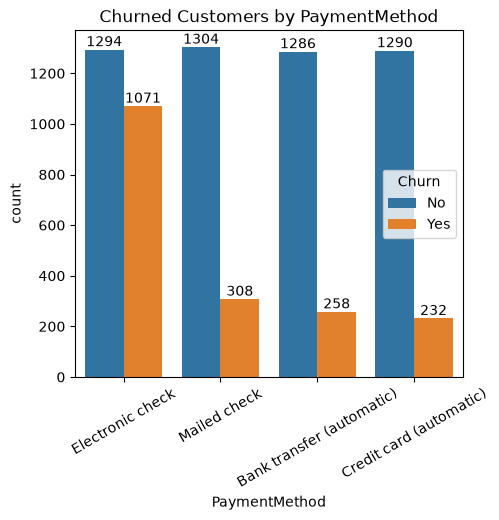

In [53]:
plt.figure(figsize = (5 , 4.5))
fig4 = sns.countplot(x = 'PaymentMethod', data = df, hue= 'Churn')
fig4.bar_label(fig4.containers[0])
fig4.bar_label(fig4.containers[1])
plt.title('Churned Customers by PaymentMethod')
plt.xticks(rotation= 30)
plt.show()

###

    Customer is likely to churn when he/she is using Electronics check

###
